# SmartCart: Customer Segmentation with PCA, K-Means and Hierarchical Clustering

**Goal:** Group 2,240 supermarket customers into meaningful segments from their demographics, income and purchase behaviour, so marketing can target each group differently.

**Type:** Unsupervised learning (no target label).

**Pipeline:** cleaning -> feature engineering -> outlier removal -> encoding -> scaling -> PCA (3D) -> choosing K (elbow + silhouette) -> K-Means and Agglomerative clustering -> cluster profiling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from kneed import KneeLocator

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

def save(name):
    plt.tight_layout()
    plt.savefig(f"../images/{name}.png", dpi=130, bbox_inches="tight")

## 1. Load and inspect

In [2]:
df = pd.read_csv("../data/smartcart_customers.csv")
print(df.shape)
display(df.head())
print("Duplicates:", df.duplicated().sum())
df.isnull().sum()[lambda s: s > 0]

(2240, 22)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


Duplicates: 0


Income    24
dtype: int64

Only `Income` has missing values (24 rows). They are filled with the **median**, which is robust to the extreme income values present in this data.

## 2. Preprocessing and feature engineering

In [3]:
df["Income"] = df["Income"].fillna(df["Income"].median())

# Age (reference year 2026)
df["Age"] = 2026 - df["Year_Birth"]

# Customer tenure in days, relative to the most recent sign-up date in the data
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)
df["Customer_Tenure_Days"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days

# Total spending across all product categories
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Total_Spending"] = df[spending_cols].sum(axis=1)

# Total children at home
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

# Simplify education into 3 levels
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate"})

# Simplify marital status into living arrangement
df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone", "Widow": "Alone",
    "Alone": "Alone", "Absurd": "Alone", "YOLO": "Alone"})

print(df["Education"].value_counts(), "\n")
print(df["Living_With"].value_counts())

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64 

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64


Engineered features compress many correlated columns into a few meaningful ones. The raw columns they replace are dropped to avoid duplicated information (`ID`, `Year_Birth`, `Marital_Status`, `Kidhome`, `Teenhome`, `Dt_Customer` and the six `Mnt*` columns). The odd marital labels `Absurd` and `YOLO` (2 rows each) are treated as living alone.

In [4]:
drop_cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"] + spending_cols
df_cleaned = df.drop(columns=drop_cols)
print(df_cleaned.shape)

(2240, 15)


## 3. Outliers

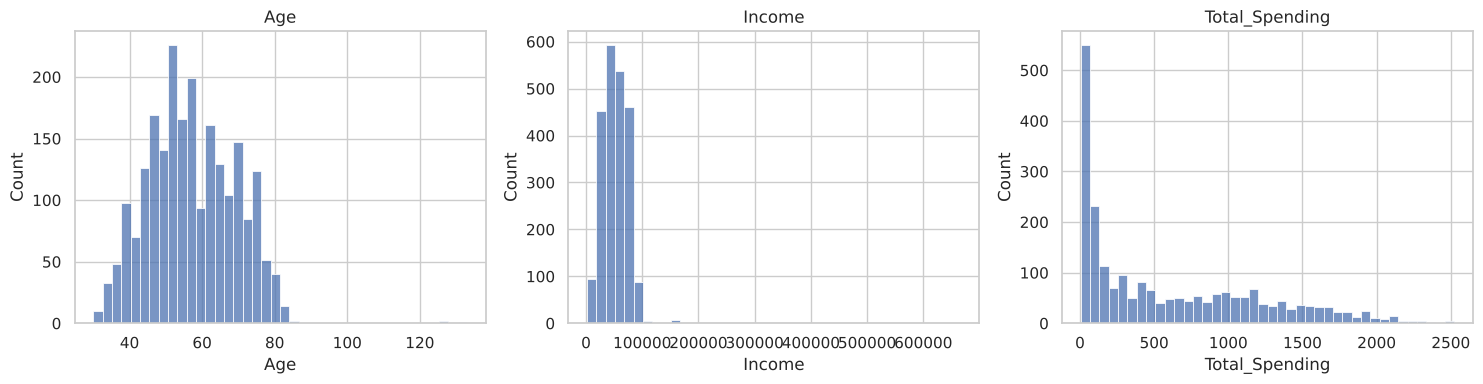

Max age: 133 | Max income: 666666.0


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["Age", "Income", "Total_Spending"]):
    sns.histplot(df_cleaned[c], bins=40, ax=a)
    a.set_title(c)
save("01_distributions_before")
plt.show()
print("Max age:", df_cleaned["Age"].max(), "| Max income:", df_cleaned["Income"].max())

There are a few impossible ages (birth years in the 1890s, i.e. age > 120) and one extreme income (666,666). These are removed with simple thresholds (`Age < 90`, `Income < 600,000`).

In [6]:
print("Rows before:", len(df_cleaned))
df_cleaned = df_cleaned[(df_cleaned["Age"] < 90) & (df_cleaned["Income"] < 600_000)]
print("Rows after :", len(df_cleaned))

Rows before: 2240
Rows after : 2236


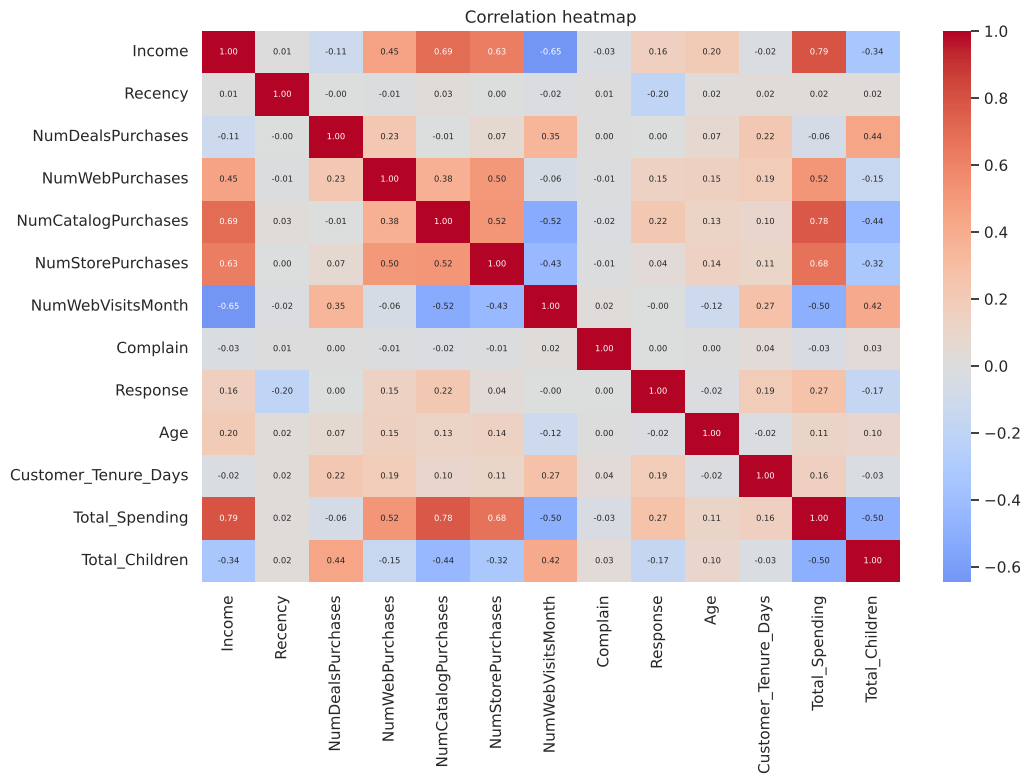

In [7]:
plt.figure(figsize=(11, 8))
sns.heatmap(df_cleaned.corr(numeric_only=True), annot=True, annot_kws={"size": 6}, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
save("02_correlation_heatmap")
plt.show()

Income correlates strongly with catalog purchases (0.69), store purchases (0.63) and total spending, and **negatively with web visits per month (-0.65)**: higher-income customers buy more and browse less.

## 4. Encoding and scaling

In [8]:
cat_cols = ["Education", "Living_With"]
ohe = OneHotEncoder()
enc = pd.DataFrame(ohe.fit_transform(df_cleaned[cat_cols]).toarray(),
                   columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)
X = pd.concat([df_cleaned.drop(columns=cat_cols), enc], axis=1)
print(X.shape)

# K-Means and PCA are distance/variance based, so features must be on the same scale
X_scaled = StandardScaler().fit_transform(X)

(2236, 18)


## 5. PCA (dimensionality reduction)
Project the 18 scaled features down to 3 components so the clusters can be visualised and the noise reduced.

In [9]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance per component:", pca.explained_variance_ratio_.round(3))
print("Total explained by 3 components :", pca.explained_variance_ratio_.sum().round(3))

Explained variance per component: [0.232 0.114 0.104]
Total explained by 3 components : 0.45


The 3 components capture about **45%** of the variance. That is enough for visualisation, but it means the clustering sees only part of the information, which is worth remembering when interpreting the results.

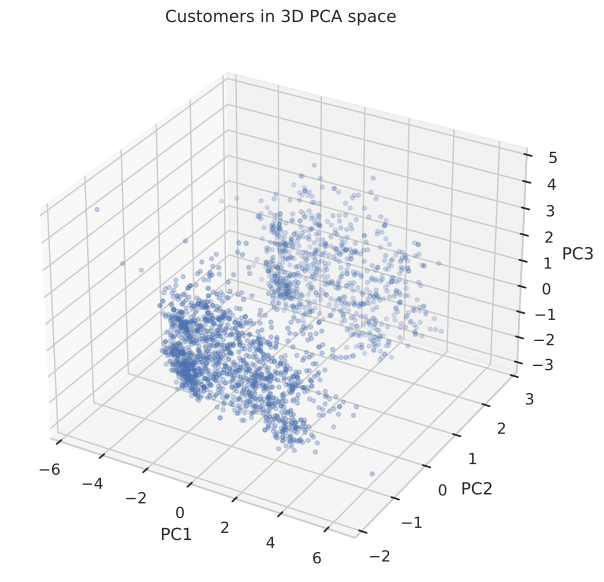

In [10]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], s=8, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Customers in 3D PCA space")
save("03_pca_3d")
plt.show()

## 6. Choosing the number of clusters (K)

Two standard methods: the **elbow method** (WCSS, where the curve bends) and the **silhouette score** (higher = better separated clusters).

Elbow suggests K = 4


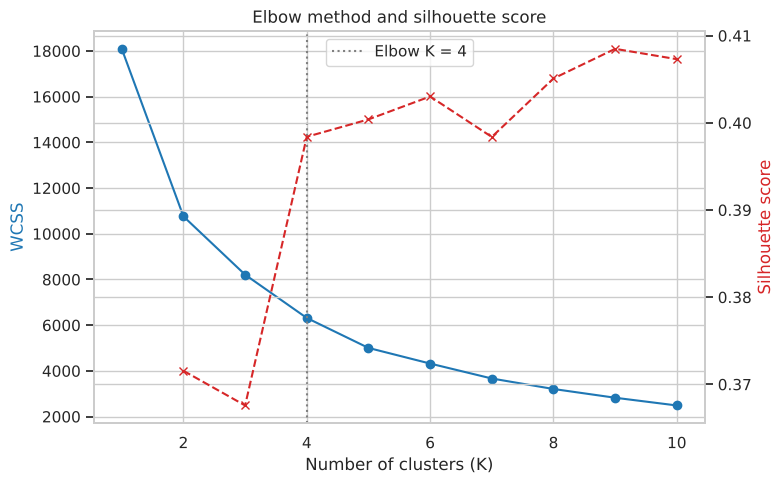

{2: 0.372, 3: 0.368, 4: 0.398, 5: 0.4, 6: 0.403, 7: 0.398, 8: 0.405, 9: 0.408, 10: 0.407}


In [11]:
k_values = range(1, 11)
wcss = [KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_pca).inertia_ for k in k_values]
optimal_k = KneeLocator(list(k_values), wcss, curve="convex", direction="decreasing").elbow
print("Elbow suggests K =", optimal_k)

sil = {k: silhouette_score(X_pca, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_pca))
       for k in range(2, 11)}

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(list(k_values), wcss, marker="o", color="tab:blue")
ax1.set_xlabel("Number of clusters (K)"); ax1.set_ylabel("WCSS", color="tab:blue")
ax1.axvline(optimal_k, color="gray", linestyle=":", label=f"Elbow K = {optimal_k}")
ax2 = ax1.twinx()
ax2.plot(list(sil.keys()), list(sil.values()), marker="x", linestyle="--", color="tab:red")
ax2.set_ylabel("Silhouette score", color="tab:red")
ax1.legend(loc="upper center")
plt.title("Elbow method and silhouette score")
save("04_elbow_silhouette")
plt.show()
print({k: round(v, 3) for k, v in sil.items()})

The elbow method points to **K = 4**. The silhouette scores are fairly flat (about 0.37 to 0.41 for every K from 2 to 10), which tells us the customers form **overlapping groups rather than sharply separated islands**. K = 4 is a reasonable and business-friendly choice (four segments are easy to act on), but it is not a sharp optimum.

## 7. Clustering with K = 4: K-Means and Agglomerative

Silhouette  K-Means      : 0.398
Silhouette  Agglomerative: 0.379
Agreement between the two (Adjusted Rand Index): 0.869


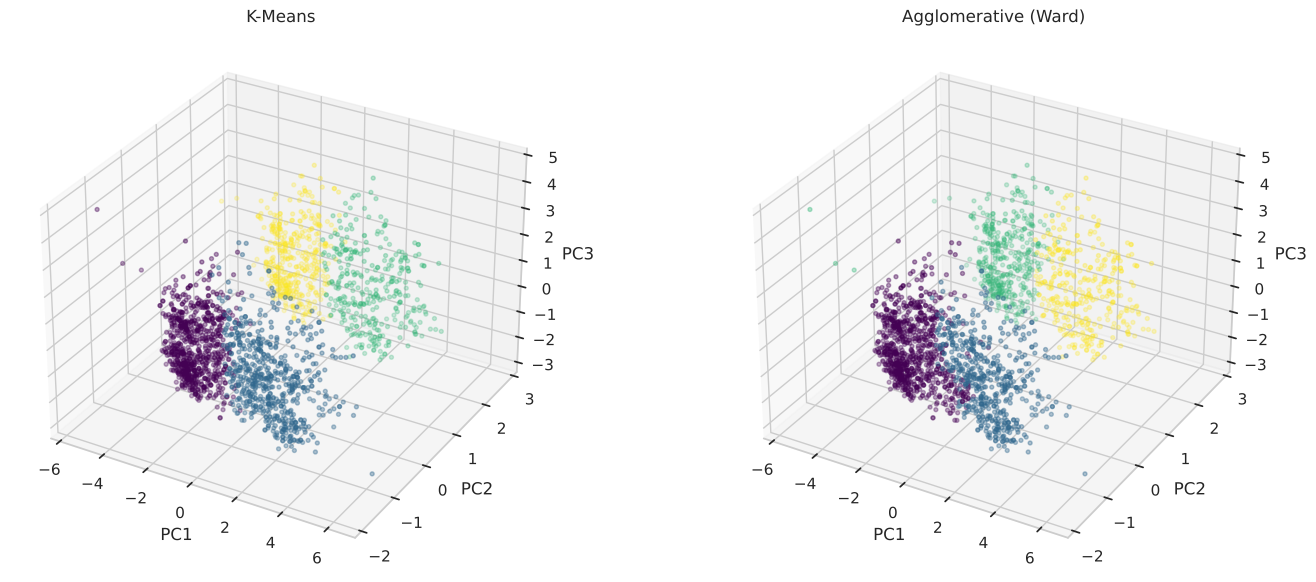

In [12]:
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
labels_km = kmeans.fit_predict(X_pca)

agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg.fit_predict(X_pca)

print("Silhouette  K-Means      :", round(silhouette_score(X_pca, labels_km), 3))
print("Silhouette  Agglomerative:", round(silhouette_score(X_pca, labels_agg), 3))
print("Agreement between the two (Adjusted Rand Index):", round(adjusted_rand_score(labels_km, labels_agg), 3))

fig = plt.figure(figsize=(15, 6))
for i, (lab, title) in enumerate([(labels_km, "K-Means"), (labels_agg, "Agglomerative (Ward)")], start=1):
    ax = fig.add_subplot(1, 2, i, projection="3d")
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=lab, cmap="viridis", s=8, alpha=0.7)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
save("05_clusters_3d")
plt.show()

Both algorithms give similar silhouette scores (K-Means is slightly higher). The **Agglomerative (Ward)** result is used for profiling below, since it is deterministic and gives well-balanced segments. The agreement score shows the two methods agree on the broad structure but not on every customer.

## 8. Cluster profiling

In [13]:
clustered = X.copy()
clustered["Cluster"] = labels_agg

summary = clustered.groupby("Cluster").mean().round(2)
summary["Customers"] = clustered["Cluster"].value_counts().sort_index()
display(summary.T)

Cluster,0,1,2,3
Income,39680.58,72808.45,36960.14,70722.68
Recency,48.91,49.20,48.32,50.50
NumDealsPurchases,2.59,1.96,2.59,1.86
NumWebPurchases,3.15,5.69,2.71,5.79
NumCatalogPurchases,0.97,5.50,0.84,5.01
NumStorePurchases,4.14,8.66,3.62,8.43
NumWebVisitsMonth,6.31,3.58,6.66,3.73
Complain,0.01,0.01,0.01,0.01
Response,0.08,0.17,0.14,0.32
Age,55.67,59.49,55.69,58.93


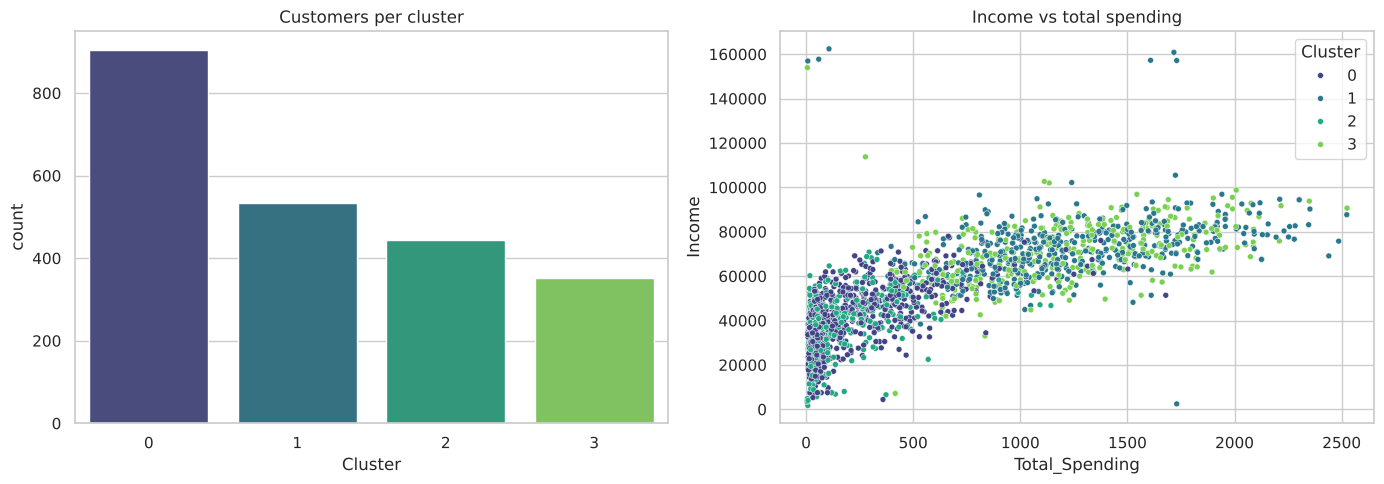

In [14]:
palette = sns.color_palette("viridis", 4)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="Cluster", data=clustered, palette=palette, hue="Cluster", legend=False, ax=ax[0])
ax[0].set_title("Customers per cluster")
sns.scatterplot(x="Total_Spending", y="Income", hue="Cluster", palette=palette, data=clustered, s=18, ax=ax[1])
ax[1].set_title("Income vs total spending")
save("06_cluster_size_income_spending")
plt.show()

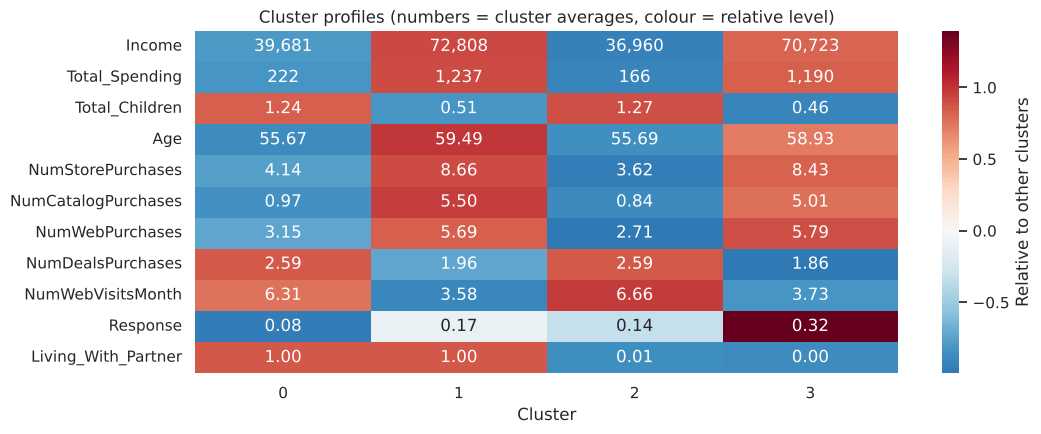

In [15]:
profile_cols = ["Income", "Total_Spending", "Total_Children", "Age", "NumStorePurchases",
                "NumCatalogPurchases", "NumWebPurchases", "NumDealsPurchases",
                "NumWebVisitsMonth", "Response", "Living_With_Partner"]
raw = clustered.groupby("Cluster")[profile_cols].mean()
z = (raw - raw.mean()) / raw.std()

plt.figure(figsize=(11, 4.5))
labels = raw.T.apply(lambda r: r.map(lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.2f}"), axis=1)
sns.heatmap(z.T, annot=labels.values, fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "Relative to other clusters"})
plt.title("Cluster profiles (numbers = cluster averages, colour = relative level)")
save("07_cluster_profile_heatmap")
plt.show()

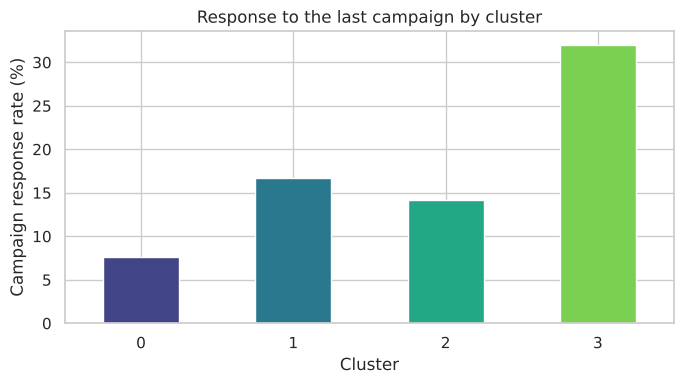

Cluster
0     7.6
1    16.7
2    14.2
3    32.0
Name: Response, dtype: float64


In [16]:
resp = clustered.groupby(["Cluster"])["Response"].mean().mul(100).round(1)
resp.plot(kind="bar", color=palette, figsize=(7, 4))
plt.ylabel("Campaign response rate (%)")
plt.title("Response to the last campaign by cluster")
plt.xticks(rotation=0)
save("08_response_by_cluster")
plt.show()
print(resp)

## 9. Segment interpretation

The four clusters are essentially **two spending tiers x two living situations**:

| Cluster | Segment name | Income | Avg. spend | Children | Lives | Notes |
|---|---|---|---|---|---|---|
| 0 | **Budget couples & families** | ~39.7k | ~222 | 1.2 | With partner | Largest group (905), many web visits, few catalog purchases |
| 1 | **Affluent couples** | ~72.8k | ~1,237 | 0.5 | With partner | Heavy catalog and store buyers, few web visits |
| 2 | **Budget solo shoppers** | ~37.0k | ~166 | 1.3 | Alone | Lowest spending, most web visits |
| 3 | **Affluent solo shoppers** | ~70.7k | ~1,190 | 0.5 | Alone | Highest campaign response (32%) |

**Business takeaways**
- The two **affluent segments (1 and 3)** are about 40% of customers but spend roughly **5 to 7 times more** than the budget segments. Catalog and in-store offers fit them best.
- The two **budget segments (0 and 2)** browse the website often but spend little: good targets for **discounts and deal-based campaigns** to convert visits into purchases.
- Customers **living alone respond to campaigns about twice as often** as those living with a partner (for example 32% vs 17% among affluent customers), which makes them the most responsive audience.

**Limitations**
- Silhouette scores are modest and flat across K, so the segments overlap; treat them as practical personas, not hard boundaries.
- PCA with 3 components keeps only about 45% of the variance.
- `Response` was one of the clustering inputs, so the response-rate comparison is partly circular and should be confirmed on held-out campaign data.
- The `Living_With` flag has a strong influence on the clusters because it is a binary feature that separates customers cleanly; trying clustering without it, or with more PCA components, would be a useful follow-up.